In [1]:
import sys
sys.path.append("../src")

import numpy as np
import torch
from sklearn.utils.class_weight import compute_class_weight
from veri import yukleyici
from modeller import mlp, basit_cnn, densenet121
from egitim import egit
from degerlendirme import olc, kaydet, grafik_ciz

csv1 = "../splits/veri1.csv"

['NORMAL', 'PNEUMONIA'] tensor([1.9378, 0.6739])
checkpoint bulundu, epoch 4'den devam ediliyor
epoch 4: kayıp 0.2168 | doğrulama doğruluk 0.925 | F1 0.909 | 240 sn
epoch 5: kayıp 0.2063 | doğrulama doğruluk 0.941 | F1 0.927 | 239 sn
epoch 6: kayıp 0.2096 | doğrulama doğruluk 0.921 | F1 0.905 | 233 sn
epoch 7: kayıp 0.1826 | doğrulama doğruluk 0.944 | F1 0.928 | 282 sn
epoch 8: kayıp 0.1762 | doğrulama doğruluk 0.932 | F1 0.916 | 301 sn
epoch 9: kayıp 0.1716 | doğrulama doğruluk 0.910 | F1 0.893 | 266 sn
epoch 10: kayıp 0.1636 | doğrulama doğruluk 0.947 | F1 0.933 | 255 sn
epoch 11: kayıp 0.1555 | doğrulama doğruluk 0.940 | F1 0.925 | 256 sn
epoch 12: kayıp 0.1660 | doğrulama doğruluk 0.934 | F1 0.920 | 253 sn
epoch 13: kayıp 0.1485 | doğrulama doğruluk 0.924 | F1 0.908 | 259 sn
epoch 14: kayıp 0.1691 | doğrulama doğruluk 0.940 | F1 0.926 | 262 sn
epoch 15: kayıp 0.1470 | doğrulama doğruluk 0.908 | F1 0.890 | 268 sn
erken durduruldu
{'accuracy': 0.8205128205128205, 'precision_macro': 0

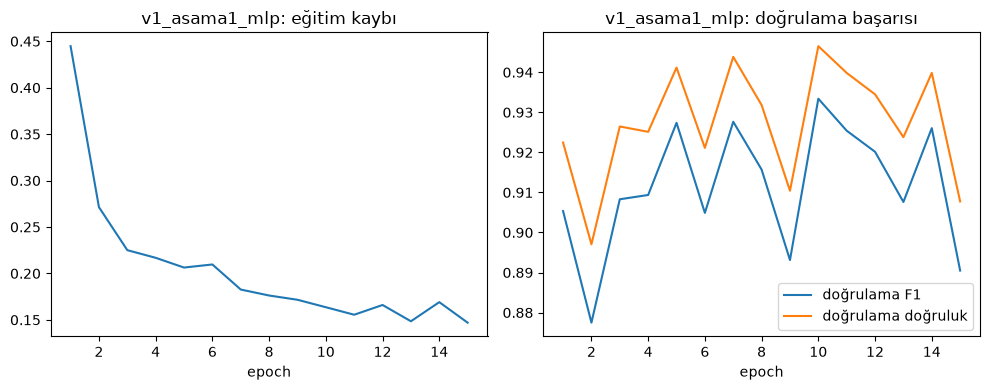

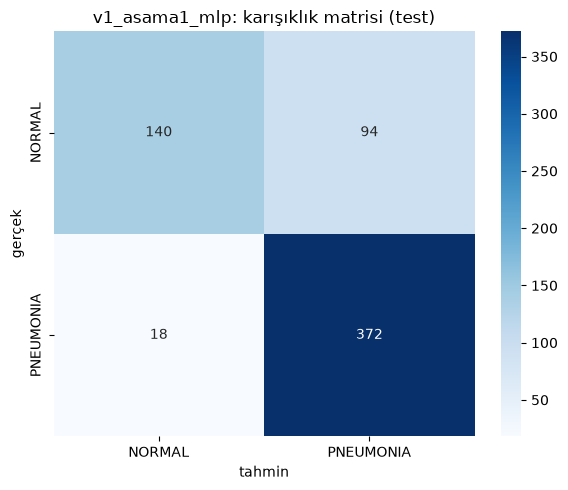

In [2]:
tr = yukleyici(csv1, "egitim", etiket_sutunu="sinif", egit=True, batch=32)
dg = yukleyici(csv1, "dogrulama", etiket_sutunu="sinif", batch=32)
te = yukleyici(csv1, "test", etiket_sutunu="sinif", batch=32)
siniflar = tr.dataset.siniflar
w = compute_class_weight("balanced", classes=np.array(siniflar), y=tr.dataset.df["sinif"])
w = torch.tensor(w, dtype=torch.float32)
print(siniflar, w)

model, gecmis = egit(mlp(len(siniflar)), tr, dg, w, epoch=20, lr=1e-3, sabir=5, kayit_adi="v1_asama1_mlp")
sonuc, kar = olc(model, te, siniflar)
kaydet("v1_asama1_mlp", model, gecmis, sonuc, kar)
print(sonuc)
print(kar)
grafik_ciz("v1_asama1_mlp")

['NORMAL', 'PNEUMONIA'] tensor([1.9378, 0.6739])
epoch 1: kayıp 0.3993 | doğrulama doğruluk 0.571 | F1 0.569 | 338 sn
epoch 2: kayıp 0.2999 | doğrulama doğruluk 0.896 | F1 0.871 | 302 sn
epoch 3: kayıp 0.2671 | doğrulama doğruluk 0.940 | F1 0.921 | 301 sn
epoch 4: kayıp 0.2543 | doğrulama doğruluk 0.908 | F1 0.888 | 299 sn
epoch 5: kayıp 0.2565 | doğrulama doğruluk 0.761 | F1 0.745 | 305 sn
epoch 6: kayıp 0.2316 | doğrulama doğruluk 0.953 | F1 0.940 | 303 sn
epoch 7: kayıp 0.2144 | doğrulama doğruluk 0.956 | F1 0.944 | 306 sn
epoch 8: kayıp 0.1719 | doğrulama doğruluk 0.862 | F1 0.843 | 304 sn
epoch 9: kayıp 0.2039 | doğrulama doğruluk 0.802 | F1 0.784 | 309 sn
epoch 10: kayıp 0.2052 | doğrulama doğruluk 0.904 | F1 0.886 | 347 sn
epoch 11: kayıp 0.1730 | doğrulama doğruluk 0.934 | F1 0.919 | 348 sn
epoch 12: kayıp 0.1710 | doğrulama doğruluk 0.967 | F1 0.957 | 332 sn
epoch 13: kayıp 0.1614 | doğrulama doğruluk 0.963 | F1 0.952 | 358 sn
epoch 14: kayıp 0.1624 | doğrulama doğruluk 0.956 

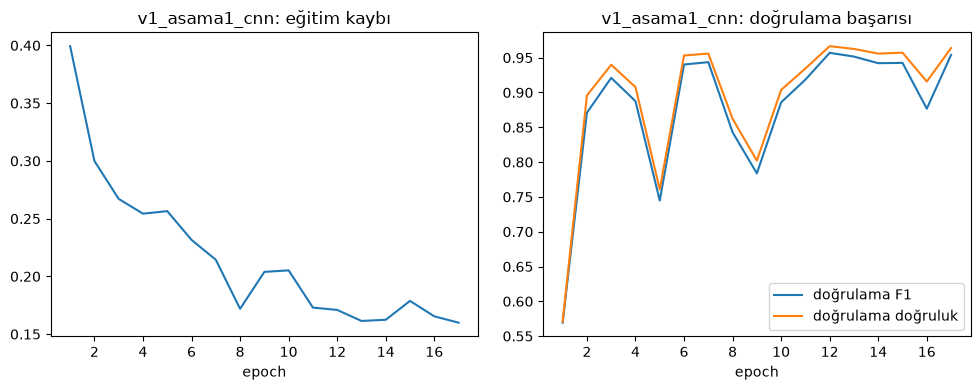

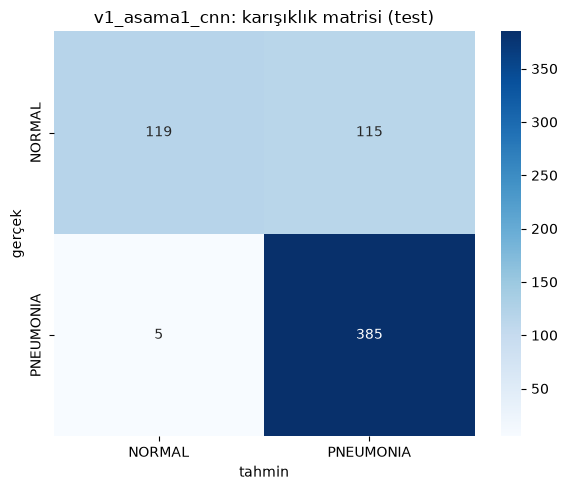

In [3]:
tr = yukleyici(csv1, "egitim", etiket_sutunu="sinif", egit=True, batch=32)
dg = yukleyici(csv1, "dogrulama", etiket_sutunu="sinif", batch=32)
te = yukleyici(csv1, "test", etiket_sutunu="sinif", batch=32)
siniflar = tr.dataset.siniflar
w = compute_class_weight("balanced", classes=np.array(siniflar), y=tr.dataset.df["sinif"])
w = torch.tensor(w, dtype=torch.float32)
print(siniflar, w)

model, gecmis = egit(basit_cnn(len(siniflar)), tr, dg, w, epoch=20, lr=1e-3, sabir=5, kayit_adi="v1_asama1_cnn")
sonuc, kar = olc(model, te, siniflar)
kaydet("v1_asama1_cnn", model, gecmis, sonuc, kar)
print(sonuc)
print(kar)
grafik_ciz("v1_asama1_cnn")